In [1]:
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision.datasets import CIFAR10
from torchvision import transforms
from torch.utils.data import Subset
import matplotlib.pyplot as plt
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import classification_report
import torchvision.models as models
import random
import math
import torchvision.models as models
from torchvision.transforms import InterpolationMode
from torch.optim import lr_scheduler
import kagglehub
import os
from sklearn.model_selection import train_test_split
from PIL import Image
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from torchvision import tv_tensors
import torch.optim.lr_scheduler as lr_scheduler
from torchvision.transforms import v2
import copy

In [2]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu'
device

'cuda'

# Загрузка данных

In [3]:
path = '../data/datasets/facial-keypoints-detection/training.csv'
df = pd.read_csv(path)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7049 entries, 0 to 7048
Data columns (total 31 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   left_eye_center_x          7039 non-null   float64
 1   left_eye_center_y          7039 non-null   float64
 2   right_eye_center_x         7036 non-null   float64
 3   right_eye_center_y         7036 non-null   float64
 4   left_eye_inner_corner_x    2271 non-null   float64
 5   left_eye_inner_corner_y    2271 non-null   float64
 6   left_eye_outer_corner_x    2267 non-null   float64
 7   left_eye_outer_corner_y    2267 non-null   float64
 8   right_eye_inner_corner_x   2268 non-null   float64
 9   right_eye_inner_corner_y   2268 non-null   float64
 10  right_eye_outer_corner_x   2268 non-null   float64
 11  right_eye_outer_corner_y   2268 non-null   float64
 12  left_eyebrow_inner_end_x   2270 non-null   float64
 13  left_eyebrow_inner_end_y   2270 non-null   float

In [4]:
class FacialKeypointsDetectionDataset:
    def __init__(self, df, transforms, is_train):
        self.transforms = transforms
        if is_train:
            self.df = df.fillna(-1)
        else:
            self.df = df.fillna(-1)

    def __len__(self):
        return self.df.shape[0]

    def __getitem__(self, idx):
        target = torch.tensor(self.df.iloc[idx, :-1].to_numpy().astype('float32'))
        coords = target.reshape((-1, 2))
        
        mask = (coords != -1).unsqueeze(0)

        str_img = self.df.iloc[idx, -1]
        img = np.array(str_img.split()).astype('uint8').reshape(96, 96)
        img = np.stack([img] * 3, axis=-1)
        img = Image.fromarray(img)
        
        coords = tv_tensors.KeyPoints(coords.unsqueeze(0), canvas_size=(96, 96))

        transformed_img, transformed_coords = self.transforms(img, coords)
        transformed_coords /= transformed_img.shape[1]
        transformed_coords[~mask] = -1.0

        transformed_coords = transformed_coords.reshape(-1)

        return transformed_img, transformed_coords

In [5]:
def draw_example(img, target):
    x = target[range(0, 30, 2)]
    y = target[range(1, 30, 2)]

    plt.imshow(img)
    for i in range(15):
        if x[i] != -1 and y[i] != -1:
            plt.scatter(x[i] * img.shape[1], y[i] * img.shape[1], c='red')

def dataset_img_to_normal_img(dataset_img):
    img = dataset_img.numpy().transpose(1, 2, 0)
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

In [6]:
def masked_rmse_loss(y_pred, y_true):
    mask = (y_true != -1)
    mse = ((y_pred - y_true) ** 2)[mask].sum() / (mask.sum() + 1e-8)
    rmse = torch.sqrt(mse + 1e-8) 
    return rmse

def masked_mse_loss(y_pred, y_true):
    mask = (y_true != -1)
    mse = ((y_pred - y_true) ** 2)[mask].sum() / (mask.sum() + 1e-8)
    return mse 

In [7]:
def train_loop(model, loss, optimizer, dataloader, train_losses, train_rmse, scheduler=None, verbose=None):
    model.train()

    batch_size = dataloader.batch_size
    all_targets = []
    all_predictions = []


    if verbose is not None:
        ver = len(dataloader) / verbose
    else:
        ver = 10

    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        y_pred = model(X)
        output = loss(y_pred, y)

        all_predictions.append(y_pred.cpu())
        all_targets.append(y.cpu())
        
        output.backward()
        optimizer.step()

        
        if (batch + 1) % int(ver) == 0:
            print(f'{(batch + 1) * batch_size}/{len(dataloader) * batch_size} | loss: {output.item()}')

            if scheduler:
                scheduler.step()
                
    all_predictions = torch.vstack(all_predictions)
    all_targets = torch.vstack(all_targets)

    train_avg_loss = loss(all_predictions, all_targets)
    train_losses.append(train_avg_loss.item())
    train_rmse.append(masked_rmse_loss(all_predictions, all_targets).item())
    print(f'Train avg loss: {train_avg_loss}')

In [8]:
def test_loop(model, loss, dataloader, test_losses, test_rmse):
    model.eval()
    batch_losses = []
    all_targets = []
    all_predictions = []

    with torch.no_grad():
        for batch, (X, y) in enumerate(dataloader):
            X, y = X.to(device), y.to(device)
    
            y_pred = model(X)
            
            output = loss(y_pred, y)
            batch_losses.append(output.item())
    
            all_predictions.append(y_pred.cpu())
            all_targets.append(y.cpu())

        all_predictions = torch.vstack(all_predictions)
        all_targets = torch.vstack(all_targets)
        
        avg_loss = loss(all_predictions, all_targets)

        print(f'{"Test avg loss:":11} {avg_loss:.7f}')        
        
        mask = (all_targets != -1)
        all_predictions = all_predictions[mask]
        all_targets = all_targets[mask]

        print('Test metrics:')
        rmse = root_mean_squared_error(all_targets, all_predictions)
        print(f'RMSE: {rmse}')
        print(f'MSE: {mean_squared_error(all_targets, all_predictions)}')
        print(f'MAE: {mean_absolute_error(all_targets, all_predictions)}')
        print(f'MAPE: {mean_absolute_percentage_error(all_targets, all_predictions)}')

        test_losses.append(avg_loss.item())
        test_rmse.append(rmse)
        return avg_loss

In [9]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# EfficientNetb0 с разморозкой некоторых слоёв features (6-8) с аугментацией + AdamW + ReduceLROnPlateau

In [10]:
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weights)

In [11]:
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [12]:
for n, p in model.named_children():
    print(n, p)

features Sequential(
  (0): Conv2dNormActivation(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU(inplace=True)
  )
  (1): Sequential(
    (0): MBConv(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): SiLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (activation): SiLU(inplace=True)
          (scale_activation): Sigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(32, 16, kernel_size=(1, 1), stride

In [13]:
regressinon_layers = nn.Sequential(
    nn.Dropout(p=0.1, inplace=True),
    nn.Linear(in_features=1280, out_features=1000, bias=True),
    nn.SiLU(),
    nn.Dropout(p=0.1),
    nn.Linear(1000, 512),
    nn.SiLU(),
    nn.Linear(512, 30)
)

In [14]:
model.classifier = regressinon_layers

In [15]:
for name, layer in model.named_parameters():
    if 'classifier' not in name:
        layer.requires_grad = False

In [16]:
for i in range(6, 9):
    for param in model.features[i].parameters():
        param.requires_grad = True

In [17]:
for name, param in list(model.named_parameters()):
    if param.requires_grad:
        print(name)

features.6.0.block.0.0.weight
features.6.0.block.0.1.weight
features.6.0.block.0.1.bias
features.6.0.block.1.0.weight
features.6.0.block.1.1.weight
features.6.0.block.1.1.bias
features.6.0.block.2.fc1.weight
features.6.0.block.2.fc1.bias
features.6.0.block.2.fc2.weight
features.6.0.block.2.fc2.bias
features.6.0.block.3.0.weight
features.6.0.block.3.1.weight
features.6.0.block.3.1.bias
features.6.1.block.0.0.weight
features.6.1.block.0.1.weight
features.6.1.block.0.1.bias
features.6.1.block.1.0.weight
features.6.1.block.1.1.weight
features.6.1.block.1.1.bias
features.6.1.block.2.fc1.weight
features.6.1.block.2.fc1.bias
features.6.1.block.2.fc2.weight
features.6.1.block.2.fc2.bias
features.6.1.block.3.0.weight
features.6.1.block.3.1.weight
features.6.1.block.3.1.bias
features.6.2.block.0.0.weight
features.6.2.block.0.1.weight
features.6.2.block.0.1.bias
features.6.2.block.1.0.weight
features.6.2.block.1.1.weight
features.6.2.block.1.1.bias
features.6.2.block.2.fc1.weight
features.6.2.blo

In [18]:
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
  (2): SiLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=1000, out_features=512, bias=True)
  (5): SiLU()
  (6): Linear(in_features=512, out_features=30, bias=True)
)

In [19]:
model = model.to(device)

In [20]:
aug_transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(224, interpolation=InterpolationMode.BICUBIC),
    v2.RandomPerspective(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [21]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
aug_train_dataset = FacialKeypointsDetectionDataset(train_df, transforms=aug_transform, is_train=True)
aug_test_dataset = FacialKeypointsDetectionDataset(test_df, transforms=aug_transform, is_train=False)

In [22]:
batch_size = 128
train_dataloader = DataLoader(aug_train_dataset, batch_size)
test_dataloader = DataLoader(aug_test_dataset, batch_size)

In [23]:
num_epochs = 20

In [24]:
loss_fn = masked_mse_loss
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-7, threshold=1e-4)
train_losses = []
train_rmse = []
test_losses = []
test_rmse = []

In [25]:
best_model = None
best_rmse = float('inf')
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses, train_rmse, verbose=5)
    val_loss = test_loop(model, loss_fn, test_dataloader, test_losses, test_rmse)
    if test_rmse[-1] < best_rmse:
        best_rmse = test_rmse[-1]
        best_model = copy.deepcopy(model)
    scheduler.step(val_loss)
    print('-' * 30)

Epoch 1
1152/5760 | loss: 0.018829060718417168
2304/5760 | loss: 0.006450053304433823
3456/5760 | loss: 0.004612212534993887
4608/5760 | loss: 0.0032291903626173735
5760/5760 | loss: 0.0037996347527951
Train avg loss: 0.02238352286318938
Test avg loss: 0.0025992
Test metrics:
RMSE: 0.051709648221731186
MSE: 0.0026738878805190325
MAE: 0.03864356875419617
MAPE: 0.08920648694038391
------------------------------
Epoch 2
1152/5760 | loss: 0.0028144153766334057
2304/5760 | loss: 0.0027292242739349604
3456/5760 | loss: 0.0026938114315271378
4608/5760 | loss: 0.002140588592737913
5760/5760 | loss: 0.001443119253963232
Train avg loss: 0.0025131998687154718
Test avg loss: 0.0021818
Test metrics:
RMSE: 0.043761830776929855
MSE: 0.00191509781870991
MAE: 0.032518260180950165
MAPE: 0.07114632427692413
------------------------------
Epoch 3
1152/5760 | loss: 0.0017777282046154141
2304/5760 | loss: 0.00207781745120883
3456/5760 | loss: 0.0021240722853690386
4608/5760 | loss: 0.0016789172077551484
576

C:\Users\Denis\AppData\Local\Temp\ipykernel_3896\1595753161.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


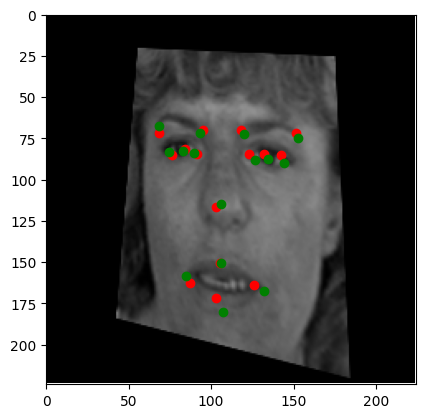

In [34]:
best_model.eval()
with torch.no_grad():
    idx = random.randint(0, len(aug_test_dataset))
    img, true_target = aug_test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = best_model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 224)
    plt.ylim(224, 0)

In [27]:
torch.save(best_model.state_dict(), '../models/lab6/efficientnet_b0_weights_1.pth')

In [58]:
idx = np.argmin(test_rmse)
train_rmse_1 = train_rmse[idx]
test_rmse_1 = test_rmse[idx]

In [60]:
print(f"Train rmse: {train_rmse_1}")
print(f"Test rmse: {test_rmse_1}")

Train rmse: 0.028300296515226364
Test rmse: 0.02651083655655384


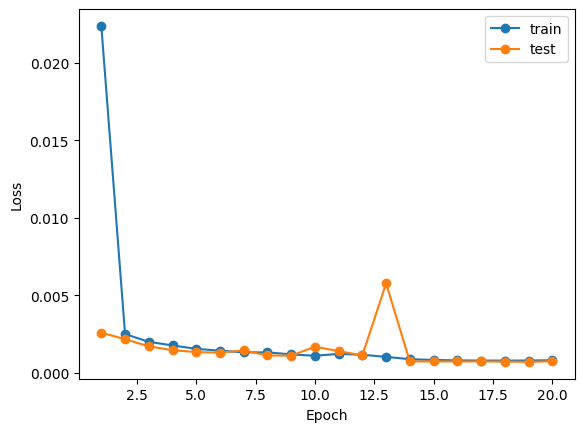

In [36]:
x = range(1, num_epochs + 1)
plt.plot(x, train_losses, label='train', marker='o')
plt.plot(x, test_losses, label='test', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# EfficientNetb0 без разморозки feature слоёв, RMSprop, без аугментации, без lr scheduler

In [12]:
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weights)

In [14]:
regressinon_layers = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features=1280, out_features=1000, bias=True),
    nn.ReLU(),
    nn.Dropout(p=0.4),
    nn.Linear(1000, 512),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(512, 30)
)

In [15]:
model.classifier = regressinon_layers

In [16]:
for name, layer in model.named_parameters():
    if 'classifier' not in name:
        layer.requires_grad = False

In [17]:
for name, param in list(model.named_parameters()):
    if param.requires_grad:
        print(name)

classifier.1.weight
classifier.1.bias
classifier.4.weight
classifier.4.bias
classifier.7.weight
classifier.7.bias


In [18]:
model = model.to(device)

In [19]:
transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(224, interpolation=InterpolationMode.BICUBIC),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [20]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
train_dataset = FacialKeypointsDetectionDataset(train_df, transforms=transform, is_train=True)
test_dataset = FacialKeypointsDetectionDataset(test_df, transforms=transform, is_train=False)

In [21]:
batch_size = 128
train_dataloader = DataLoader(train_dataset, batch_size)
test_dataloader = DataLoader(test_dataset, batch_size)

In [22]:
num_epochs = 10

In [23]:
loss_fn = masked_mse_loss
optimizer = torch.optim.RMSprop(model.parameters(), lr=1e-4, weight_decay=1e-2)
train_losses = []
train_rmse = []
test_losses = []
test_rmse = []

In [24]:
best_model = None
best_rmse = float('inf')
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses, train_rmse, verbose=5)
    val_loss = test_loop(model, loss_fn, test_dataloader, test_losses, test_rmse)
    if test_rmse[-1] < best_rmse:
        best_rmse = test_rmse[-1]
        best_model = copy.deepcopy(model)
    print('-' * 30)

Epoch 1
1152/5760 | loss: 0.03263929858803749
2304/5760 | loss: 0.025304686278104782
3456/5760 | loss: 0.028472624719142914
4608/5760 | loss: 0.025988738983869553
5760/5760 | loss: 0.009230132214725018
Train avg loss: 0.039553411304950714
Test avg loss: 0.0294283
Test metrics:
RMSE: 0.17154670751811973
MSE: 0.029428272860307313
MAE: 0.14245144645324184
MAPE: 0.2788935131238685
------------------------------
Epoch 2
1152/5760 | loss: 0.016006169840693474
2304/5760 | loss: 0.022099537774920464
3456/5760 | loss: 0.0188074242323637
4608/5760 | loss: 0.017593413591384888
5760/5760 | loss: 0.005965294782072306
Train avg loss: 0.01975276507437229
Test avg loss: 4.8968978
Test metrics:
RMSE: 2.212893556704606
MSE: 4.896897893304762
MAE: 0.12628027385450694
MAPE: 0.24661207731249601
------------------------------
Epoch 3


KeyboardInterrupt: 

C:\Users\Denis\AppData\Local\Temp\ipykernel_14184\3698558790.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


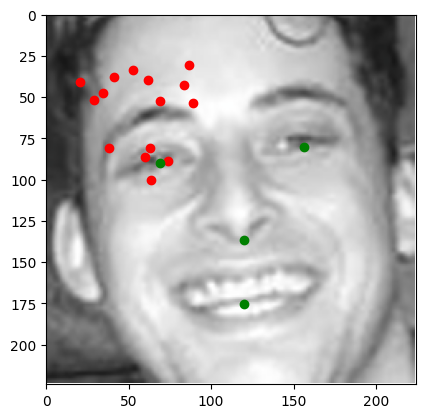

In [37]:
best_model.eval()
with torch.no_grad():
    idx = random.randint(0, len(train_dataset))
    img, true_target = train_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = best_model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 224)
    plt.ylim(224, 0)

In [96]:
torch.save(best_model.state_dict(), '../models/lab6/efficientnet_b0_weights_2.pth')

In [97]:
idx = np.argmin(test_rmse)
train_rmse_2 = train_rmse[idx]
test_rmse_2 = test_rmse[idx]

In [98]:
print(f"Train rmse: {train_rmse_2}")
print(f"Test rmse: {test_rmse_2}")

Train rmse: 3.570956230163574
Test rmse: 0.10964305527272315


RuntimeError: Can't call numpy() on Tensor that requires grad. Use tensor.detach().numpy() instead.

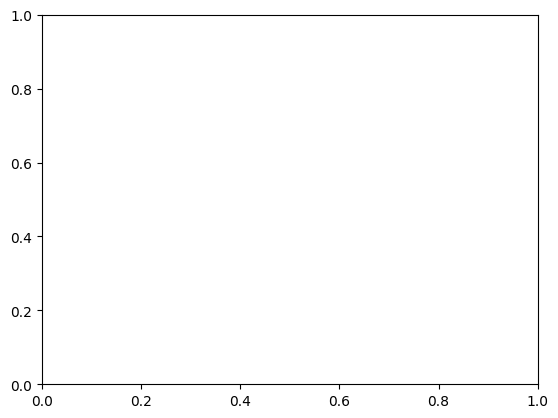

In [44]:
x = range(1, num_epochs + 1)
plt.plot(x, train_losses, label='train', marker='o')
plt.plot(x, test_losses, label='test', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

In [45]:
print(train_losses)

[tensor(83.1373, grad_fn=<DivBackward0>), tensor(0.0108, grad_fn=<DivBackward0>), tensor(0.0085, grad_fn=<DivBackward0>), tensor(0.0096, grad_fn=<DivBackward0>), tensor(0.0066, grad_fn=<DivBackward0>), tensor(0.0057, grad_fn=<DivBackward0>), tensor(0.0071, grad_fn=<DivBackward0>), tensor(0.0050, grad_fn=<DivBackward0>), tensor(0.0052, grad_fn=<DivBackward0>), tensor(0.0051, grad_fn=<DivBackward0>), tensor(0.0046, grad_fn=<DivBackward0>), tensor(0.0049, grad_fn=<DivBackward0>), tensor(0.0042, grad_fn=<DivBackward0>), tensor(0.0043, grad_fn=<DivBackward0>), tensor(0.0046, grad_fn=<DivBackward0>), tensor(0.0039, grad_fn=<DivBackward0>), tensor(0.0039, grad_fn=<DivBackward0>), tensor(0.0040, grad_fn=<DivBackward0>), tensor(0.0037, grad_fn=<DivBackward0>), tensor(0.0040, grad_fn=<DivBackward0>)]


# EfficientNetb0 без аугментации

In [123]:
weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weights)

In [124]:
regressinon_layers = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280, out_features=1000, bias=True),
    nn.ReLU(),
    nn.Dropout(p=0.3),
    nn.Linear(1000, 512),
    nn.ReLU(),
    nn.Linear(512, 30)
)

In [125]:
model.classifier = regressinon_layers

In [126]:
for name, layer in model.named_parameters():
    if 'classifier' not in name:
        layer.requires_grad = False

In [127]:
for name, param in list(model.named_parameters()):
    if param.requires_grad:
        print(name)

classifier.1.weight
classifier.1.bias
classifier.4.weight
classifier.4.bias
classifier.6.weight
classifier.6.bias


In [128]:
model = model.to(device)

In [129]:
transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(224, interpolation=InterpolationMode.BICUBIC),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [130]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
train_dataset = FacialKeypointsDetectionAugmentedDataset(train_df, transforms=transform, is_train=True)
test_dataset = FacialKeypointsDetectionAugmentedDataset(test_df, transforms=transform, is_train=False)

In [131]:
batch_size = 128
train_dataloader = DataLoader(train_dataset, batch_size)
test_dataloader = DataLoader(test_dataset, batch_size)

In [132]:
num_epochs = 40

In [133]:
loss_fn = masked_mse_loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-7, threshold=1e-4)
scheduler_2 = lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
train_losses = []
test_losses = []

In [134]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses, verbose=5)
    val_loss = test_loop(model, loss_fn, test_dataloader, test_losses)
    scheduler.step(val_loss)
    print('-' * 30)

Epoch 1
1152/5760 | loss: 1340.7386474609375
2304/5760 | loss: 1039.7850341796875
3456/5760 | loss: 533.6138916015625
4608/5760 | loss: 361.4623107910156
5760/5760 | loss: 321.9097900390625
Train avg loss: 1337.5372938368055
Test avg loss: 247.8639336
Test metrics:
RMSE: 16.0876522064209
MSE: 258.81256103515625
MAE: 12.20428466796875
MAPE: 0.11219174414873123
------------------------------
Epoch 2
1152/5760 | loss: 350.5196533203125
2304/5760 | loss: 340.1854248046875
3456/5760 | loss: 303.0162658691406
4608/5760 | loss: 268.75958251953125
5760/5760 | loss: 267.0882568359375
Train avg loss: 309.6965552435981
Test avg loss: 1361104.8999863
Test metrics:
RMSE: 1182.078857421875
MSE: 1397310.5
MAE: 41.90753936767578
MAPE: 0.35735902190208435
------------------------------
Epoch 3
1152/5760 | loss: 274.39569091796875
2304/5760 | loss: 258.8648376464844
3456/5760 | loss: 203.20709228515625
4608/5760 | loss: 236.13949584960938
5760/5760 | loss: 366.69384765625
Train avg loss: 274.44412299262

KeyboardInterrupt: 

C:\Users\Denis\AppData\Local\Temp\ipykernel_2020\1186917405.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


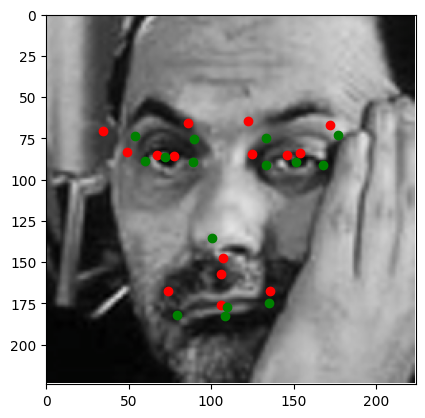

In [121]:
model.eval()
with torch.no_grad():
    idx = random.randint(0, len(test_dataset))
    img, true_target = test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, 224)
    plt.ylim(224, 0)

# EfficientNetb1 без аугментации

In [170]:
weights = models.EfficientNet_B1_Weights.IMAGENET1K_V1
model = models.efficientnet_b1(weights=weights)

In [171]:
regressinon_layers = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280, out_features=1000, bias=True),
    nn.SiLU(),
    nn.Dropout(p=0.3),
    nn.Linear(1000, 512),
    nn.SiLU(),
    nn.Linear(512, 30)
)

In [172]:
model.classifier = regressinon_layers

In [173]:
for name, layer in model.named_parameters():
    if 'classifier' not in name:
        layer.requires_grad = False

In [174]:
for i in range(6, 9):
    for param in model.features[i].parameters():
        param.requires_grad = True

In [175]:
for name, param in list(model.named_parameters()):
    if param.requires_grad:
        print(name)

features.6.0.block.0.0.weight
features.6.0.block.0.1.weight
features.6.0.block.0.1.bias
features.6.0.block.1.0.weight
features.6.0.block.1.1.weight
features.6.0.block.1.1.bias
features.6.0.block.2.fc1.weight
features.6.0.block.2.fc1.bias
features.6.0.block.2.fc2.weight
features.6.0.block.2.fc2.bias
features.6.0.block.3.0.weight
features.6.0.block.3.1.weight
features.6.0.block.3.1.bias
features.6.1.block.0.0.weight
features.6.1.block.0.1.weight
features.6.1.block.0.1.bias
features.6.1.block.1.0.weight
features.6.1.block.1.1.weight
features.6.1.block.1.1.bias
features.6.1.block.2.fc1.weight
features.6.1.block.2.fc1.bias
features.6.1.block.2.fc2.weight
features.6.1.block.2.fc2.bias
features.6.1.block.3.0.weight
features.6.1.block.3.1.weight
features.6.1.block.3.1.bias
features.6.2.block.0.0.weight
features.6.2.block.0.1.weight
features.6.2.block.0.1.bias
features.6.2.block.1.0.weight
features.6.2.block.1.1.weight
features.6.2.block.1.1.bias
features.6.2.block.2.fc1.weight
features.6.2.blo

In [176]:
model = model.to(device)

In [177]:
transform = v2.Compose([
    v2.ToImage(),
    v2.Resize(256, interpolation=InterpolationMode.BICUBIC),
    v2.CenterCrop(240),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean, std)
])

In [178]:
df = pd.read_csv(path)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['left_eye_inner_corner_x'].notna(), random_state=42)
train_dataset = FacialKeypointsDetectionAugmentedDataset(train_df, transforms=transform, is_train=True)
test_dataset = FacialKeypointsDetectionAugmentedDataset(test_df, transforms=transform, is_train=False)

In [179]:
batch_size = 128
train_dataloader = DataLoader(train_dataset, batch_size)
test_dataloader = DataLoader(test_dataset, batch_size)

In [180]:
num_epochs = 10

In [181]:
loss_fn = masked_mse_loss
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-6, threshold=1e-4)
scheduler_2 = lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)
train_losses = []
test_losses = []

In [182]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(model, loss_fn, optimizer, train_dataloader, train_losses, verbose=5)
    val_loss = test_loop(model, loss_fn, test_dataloader, test_losses)
    scheduler_2.step()
    print('-' * 30)

Epoch 1
1152/5760 | loss: 1058.4422607421875
2304/5760 | loss: 339.98870849609375
3456/5760 | loss: 159.19126892089844
4608/5760 | loss: 122.93919372558594
5760/5760 | loss: 99.6280517578125
Train avg loss: 1177.2295649210612
Test avg loss: 106.4473623
Test metrics:
RMSE: 10.453474998474121
MSE: 109.275146484375
MAE: 7.387270450592041
MAPE: 0.08078555017709732
------------------------------
Epoch 2
1152/5760 | loss: 101.43069458007812
2304/5760 | loss: 126.72506713867188
3456/5760 | loss: 100.48880767822266
4608/5760 | loss: 97.9269027709961
5760/5760 | loss: 83.07306671142578
Train avg loss: 115.41690995958116
Test avg loss: 95.7002557
Test metrics:
RMSE: 9.875127792358398
MSE: 97.51814270019531
MAE: 6.910244464874268
MAPE: 0.07565461099147797
------------------------------
Epoch 3
1152/5760 | loss: 89.32405853271484
2304/5760 | loss: 118.05896759033203
3456/5760 | loss: 96.19941711425781
4608/5760 | loss: 94.60081481933594
5760/5760 | loss: 64.33399963378906
Train avg loss: 106.58898

C:\Users\Denis\AppData\Local\Temp\ipykernel_9480\763437833.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  img = torch.tensor(img).unsqueeze(dim=0).to(device)


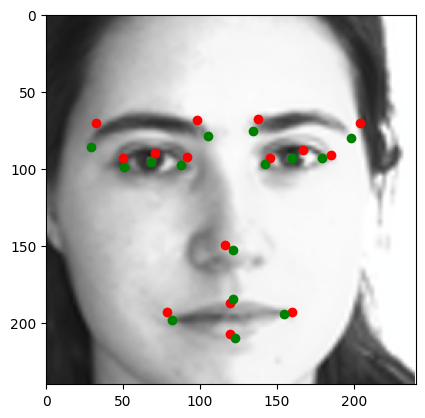

In [211]:
model.eval()
with torch.no_grad():
    idx = random.randint(0, len(test_dataset))
    img, true_target = test_dataset[idx]
    img_vis = dataset_img_to_normal_img(img)

    
    img = torch.tensor(img).unsqueeze(dim=0).to(device)
    pred_target = model(img).cpu().detach().numpy()

    draw_example(img_vis, pred_target[0])
    plt.imshow(img_vis)
    for i in range(0, 30, 2):
        x, y = true_target[i] * img.shape[2], true_target[i+1] * img.shape[2]
        if x != -1 and y != -1:
            plt.scatter(x, y, c='green')
    plt.xlim(0, img.shape[2])
    plt.ylim(img.shape[2], 0)

In [212]:
print(f'Train loss: {train_losses[-1]}')
print(f'Test loss: {test_losses[-1]}')

Train loss: 84.06357913547092
Test loss: 78.0639238357544


# Своя модель

In [28]:
for name, layer in model.named_parameters():
    if 'classifier' not in name:
        layer.requires_grad = False

In [ ]:
class ConvClassificationModel(nn.Module):
    def __init__(self, h=96, w=96):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ELU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ELU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ELU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(32 * h//2 * w//2, 512),
            nn.BatchNorm1d(512),
            nn.ELU(),
            nn.Linear(512, 30),
        )

    def forward(self, x):
        x = self.conv_stack(x)
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

In [ ]:
my_model = ConvClassificationModel().to(device)

loss_fn = masked_mse_loss
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-9, threshold=1e-3)
scheduler_2 = lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
train_losses = []
test_losses = []

In [ ]:
for i in range(num_epochs):
    print(f'Epoch {i+1}')
    train_loop(my_model, loss_fn, optimizer, train_dataloader, train_losses, verbose=5)
    val_loss = test_loop(my_model, loss_fn, test_dataloader, test_losses)
    scheduler.step(val_loss)
    print('-' * 30)

# Визуализация слоёв

In [ ]:
def visualize_conv(layers, num_epochs, size=128, n_filters=16, lr=1e-2):
    """
    На вход подаётся часть слоёв сети, где последним слоем является свёрточный слой, который хотим визуализировать
    """
    result = {}
    
    conv = layers[-1]
    n_filters = min(conv.weight.shape[0], n_filters)

    for param in layers.parameters():
        param.requires_grad = False

    rand_idx = random.sample(range(conv.weight.shape[0]), k=n_filters)
    for i in rand_idx:
        img = torch.rand((1, 3, size, size)).to(device)
        img.requires_grad = True

        optimizer = torch.optim.Adam([img], lr=lr)

        for e in range(num_epochs):
            optimizer.zero_grad()

            output = layers(img)
            loss = -output[0][i].mean()

            loss.backward()
            optimizer.step()

        img = img.squeeze(dim=0)
        img = img.permute(1, 2, 0).cpu().detach()
        final_img = (img - img.min()) / (img.max() - img.min() + 1e-5)
        
        result[f'filter_{i}'] = final_img
        
    return result

In [ ]:
def draw_imgs(imgs, titles=None, n_cols=8, size=4):
    n_rows = math.ceil(len(imgs) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * n_rows))
    axes = axes.flatten()
    for i in range(len(imgs)):
        ax = axes[i]
        ax.imshow(imgs[i])
        if titles:
            ax.set_title(titles[i])
        ax.axis('off')
        
    for j in range(i, len(axes)):
        ax = axes[j]
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
for name, param in list(model.named_children()):
    print(name, param)

In [ ]:
n_layer = 8
layers = nn.Sequential(
    *(model.features[:4], model.features[4][0].block[0][0])
).to(device)

In [ ]:
layers

In [ ]:
visualization = visualize_conv(
    layers,
    num_epochs=100,
    size=256,
    n_filters=16,
    lr=1e1
)
imgs = list(visualization.values())
titles = list(visualization.keys())

In [ ]:
draw_imgs(
    imgs, 
    titles,
    n_cols=4,
    size=4
)